<a href="https://colab.research.google.com/github/sachin23-an/quant-researcher-practical-lab/blob/main/Quant_Researcher_Practical_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quant Researcher — Practical Lab 2
### Regime Classification — Part 4 ka practical version

Theory: regime ko classification problem ki tarah frame karna, logistic regression scratch se, decision tree -> gradient boosting -> XGBoost, classifier ko sahi se evaluate karna, aur 4-point leakage audit.


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
import xgboost as xgb

np.random.seed(7)
plt.rcParams['figure.figsize'] = (8,4)


## 0. Data — synthetic "high vol vs low vol" regime

Real NSE option-implied-vol data lena ideal hoga, lekin regime-labeling ke concept ko practice karne ke liye hum ek realized-volatility-based regime banate hain jo NIFTY jaisa behave kare (fat tails, vol clustering) — GARCH-style simulated returns se.


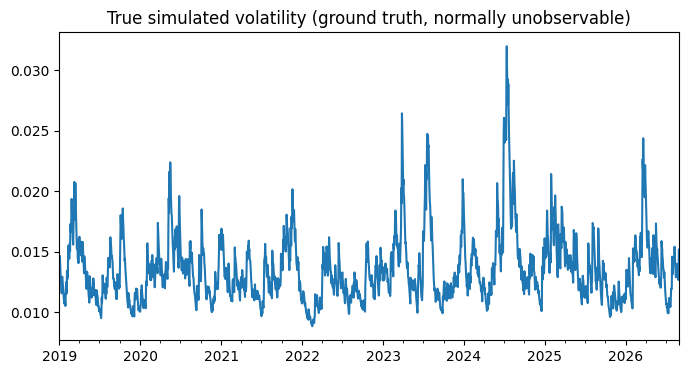

In [2]:
def simulate_garch_like(n=2000, omega=1e-5, alpha=0.1, beta=0.85):
    returns = np.zeros(n)
    sigma2 = np.zeros(n)
    sigma2[0] = omega/(1-alpha-beta)
    for t in range(1, n):
        sigma2[t] = omega + alpha*returns[t-1]**2 + beta*sigma2[t-1]
        returns[t] = np.random.randn()*np.sqrt(sigma2[t])
    dates = pd.bdate_range('2019-01-01', periods=n)
    return pd.Series(returns, index=dates), pd.Series(np.sqrt(sigma2), index=dates)

returns, true_vol = simulate_garch_like()
price = 100*(1+returns).cumprod()
true_vol.plot(title='True simulated volatility (ground truth, normally unobservable)')
plt.show()


## A. Framing "regime" as a classification problem

**Label definition:** agla 10-din realized volatility, median se zyada ho to "high-vol regime" (1), warna "low-vol regime" (0). Ye ek deliberately simple, defensible label hai — jitna simple label utna kam room for leakage.


In [3]:
future_realized_vol = returns.shift(-10).rolling(10).std() * np.sqrt(252)
label = (future_realized_vol > future_realized_vol.median()).astype(int)
label.name = 'regime_label'

print(label.value_counts())


regime_label
0    1010
1     990
Name: count, dtype: int64


## E. Feature Engineering for Regimes (before B/C/D on purpose — features pehle chahiye model train karne ke liye)

Saari features sirf **past** data se — kabhi bhi `future_realized_vol` ya us din ke close se nahi.


In [4]:
feat = pd.DataFrame(index=returns.index)
feat['realized_vol_10']  = returns.rolling(10).std().shift(1) * np.sqrt(252)
feat['realized_vol_30']  = returns.rolling(30).std().shift(1) * np.sqrt(252)
feat['abs_return_5']     = returns.abs().rolling(5).mean().shift(1)
feat['return_skew_30']   = returns.rolling(30).skew().shift(1)
feat['vol_of_vol']       = returns.rolling(10).std().rolling(10).std().shift(1)

dataset = pd.concat([feat, label], axis=1).dropna()
dataset.head()


,realized_vol_10,realized_vol_30,abs_return_5,return_skew_30,vol_of_vol,regime_label
2019-02-12,0.273694,0.196269,0.014069,-0.084788,0.002831,1
2019-02-13,0.263383,0.197000,0.015238,-0.032092,0.002643,1
2019-02-14,0.244049,0.186025,0.013744,-0.049973,0.002497,1
2019-02-15,0.261236,0.192001,0.015742,-0.131571,0.002303,1
2019-02-18,0.283512,0.202937,0.014613,-0.116072,0.002011,1


## B. Logistic Regression — Derived From Scratch

Sklearn use karna easy hai, lekin interview mein kabhi "derive/implement logistic regression" bol sakte hain. Gradient descent se khud likhte hain — sigmoid, cross-entropy loss, gradient.


In [5]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

def train_logistic_regression(X, y, lr=0.1, n_iter=500):
    X = np.column_stack([np.ones(len(X)), X])   # add intercept
    w = np.zeros(X.shape[1])
    for _ in range(n_iter):
        z = X @ w
        p = sigmoid(z)
        grad = X.T @ (p - y) / len(y)             # cross-entropy gradient
        w -= lr * grad
    return w

def predict_logistic(X, w):
    X = np.column_stack([np.ones(len(X)), X])
    return sigmoid(X @ w)

# quick sanity check on 2 features, standardized
Xs = (dataset[['realized_vol_10','realized_vol_30']] - dataset[['realized_vol_10','realized_vol_30']].mean()) \
     / dataset[['realized_vol_10','realized_vol_30']].std()
w = train_logistic_regression(Xs.values, dataset['regime_label'].values)
pred_prob = predict_logistic(Xs.values, w)
print('learned weights (intercept, vol_10, vol_30):', np.round(w,3))
print('train accuracy:', ((pred_prob>0.5).astype(int) == dataset['regime_label']).mean().round(3))


learned weights (intercept, vol_10, vol_30): [0.008 0.663 0.161]
train accuracy: 0.638


**Note:** ye purposely training set pe hi fit+predict kiya — sirf dikhane ke liye ki formula sahi hai. Asli evaluation hamesha walk-forward hona chahiye (Section F).


## C. Decision Trees → Gradient Boosting → XGBoost


In [6]:
feature_cols = ['realized_vol_10','realized_vol_30','abs_return_5','return_skew_30','vol_of_vol']
split = int(len(dataset)*0.7)
train, test = dataset.iloc[:split], dataset.iloc[split:]
Xtr, ytr = train[feature_cols], train['regime_label']
Xte, yte = test[feature_cols], test['regime_label']

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)
gb   = GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=0).fit(Xtr, ytr)
xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=2, eval_metric='logloss', random_state=0).fit(Xtr, ytr)

for name, model in [('DecisionTree', tree), ('GradientBoosting', gb), ('XGBoost', xgb_model)]:
    acc = model.score(Xte, yte)
    print(f'{name:18s} test accuracy: {acc:.3f}')


DecisionTree       test accuracy: 0.575
GradientBoosting   test accuracy: 0.613
XGBoost            test accuracy: 0.614


## D. Evaluating a Classifier Properly

Accuracy akeli misleading ho sakti hai (especially agar regimes imbalanced hon). Precision, recall, confusion matrix, aur AUC saath dekhna zaroori hai.


In [7]:
def evaluate_classifier(model, X, y, name):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:,1]
    print(f'--- {name} ---')
    print('confusion matrix [[TN,FP],[FN,TP]]:')
    print(confusion_matrix(y, pred))
    print(f'precision: {precision_score(y, pred):.3f}  recall: {recall_score(y, pred):.3f}  AUC: {roc_auc_score(y, proba):.3f}')
    print()

for name, model in [('DecisionTree', tree), ('GradientBoosting', gb), ('XGBoost', xgb_model)]:
    evaluate_classifier(model, Xte, yte, name)


--- DecisionTree ---
confusion matrix [[TN,FP],[FN,TP]]:
[[168  76]
 [175 172]]
precision: 0.694  recall: 0.496  AUC: 0.587

--- GradientBoosting ---
confusion matrix [[TN,FP],[FN,TP]]:
[[157  87]
 [142 205]]
precision: 0.702  recall: 0.591  AUC: 0.625

--- XGBoost ---
confusion matrix [[TN,FP],[FN,TP]]:
[[152  92]
 [136 211]]
precision: 0.696  recall: 0.608  AUC: 0.659



**Kya dekhna hai:** agar precision high lekin recall low hai, model conservative hai (high-vol regime miss kar raha hai). Interview mein "why not just report accuracy" — iska jawab: class imbalance ke saath accuracy chhupa sakti hai ki model ek class ko almost ignore kar raha hai.


## F. Walk-Forward ML & the 4-Point Leakage Audit

4-point audit (apna checklist, har model train karne se pehle khud se poochna):
1. Kya koi feature future information use kar rahi hai? (shift sahi se laga?)
2. Kya label definition khud future ko overlap karti hai training window ke saath? (purge/embargo chahiye?)
3. Kya scaling/normalization sirf training fold pe fit hui, poore dataset pe nahi?
4. Kya walk-forward split train-before-test order maintain karta hai, random split nahi?


In [8]:
def walk_forward_splits(n_rows, train_size, test_size, step=None):
    step = step or test_size
    splits, start = [], 0
    while start + train_size + test_size <= n_rows:
        splits.append((range(start, start+train_size), range(start+train_size, start+train_size+test_size)))
        start += step
    return splits

folds = walk_forward_splits(len(dataset), train_size=400, test_size=100)
fold_aucs = []

for train_idx, test_idx in folds:
    tr, te = dataset.iloc[list(train_idx)], dataset.iloc[list(test_idx)]
    # audit point 3: scaler fit ONLY on train fold
    mean, std = tr[feature_cols].mean(), tr[feature_cols].std()
    Xtr_s = (tr[feature_cols]-mean)/std
    Xte_s = (te[feature_cols]-mean)/std

    model = xgb.XGBClassifier(n_estimators=100, max_depth=2, eval_metric='logloss', random_state=0)
    model.fit(Xtr_s, tr['regime_label'])
    proba = model.predict_proba(Xte_s)[:,1]
    fold_aucs.append(roc_auc_score(te['regime_label'], proba))

print('walk-forward AUC per fold:', np.round(fold_aucs,3))
print('mean walk-forward AUC:', round(np.mean(fold_aucs),3))


walk-forward AUC per fold: [0.417 0.695 0.394 0.568 0.631 0.379 0.366 0.668 0.236 0.481 0.627 0.821
 0.525 0.377 0.584]
mean walk-forward AUC: 0.518


**Compare:** walk-forward AUC vs ek single in-sample AUC — agar walk-forward number kaafi kam hai, model sirf historical noise fit kar raha tha, genuine regime signal nahi seekha.


## G. End-to-End Regime Project — summary

Pipeline jo abhi bana: raw returns → realized-vol-based label → backward-only features → walk-forward trained XGBoost → audited for leakage → evaluated with precision/recall/AUC, not just accuracy.

Agar interviewer bole "build me a regime detector right now" — yahi 6-step skeleton (data → label → features → walk-forward split → model → proper evaluation) likh do, formula yaad na bhi ho to bhi structure sahi dikhega.
